Begin

In [3]:
import sys
print(sys.executable)

/opt/anaconda3/envs/cicids-ids/bin/python


In [4]:
import pandas as pd
import sklearn
import tensorflow as tf
import xplique

print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("TensorFlow:", tf.__version__)
print("Xplique: imported successfully")

Pandas: 3.0.6
Scikit-learn: 1.9.1
TensorFlow: 2.15.1
Xplique: imported successfully


In [5]:
from pathlib import Path

DATA_DIR = Path("data/raw/MachineLearningCVE")

print("Current directory:", Path.cwd())
print("Dataset found:", DATA_DIR.exists())
print("CSV files:", len(list(DATA_DIR.glob("*.csv"))))

Current directory: /Users/arian/Documents/cicids2017-xai-ids
Dataset found: True
CSV files: 8


In [6]:
import numpy as np
import pandas as pd

files = sorted(DATA_DIR.glob("*.csv"))
frames, labels = [], []

for file in files:
    data = pd.read_csv(file, low_memory=False)
    data.columns = data.columns.str.strip()

    labels.append(
        data.pop("Label").str.strip().ne("BENIGN").astype("int8")
    )

    data = data.apply(pd.to_numeric, errors="coerce").astype("float32")
    data.replace([np.inf, -np.inf], np.nan, inplace=True)
    frames.append(data)

X = pd.concat(frames, ignore_index=True)
y = pd.concat(labels, ignore_index=True)

del frames, labels

print("Samples and features:", X.shape)
print("0 = BENIGN, 1 = ATTACK")
print(y.value_counts())

Samples and features: (2830743, 78)
0 = BENIGN, 1 = ATTACK
Label
0    2273097
1     557646
Name: count, dtype: int64


In [7]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=2/3, random_state=42, stratify=y_temp
)

del X, y, X_temp, y_temp

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (1981520, 78)
Validation: (283074, 78)
Test: (566149, 78)


In [8]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler

imputer = SimpleImputer(strategy="median")

X_train = imputer.fit_transform(X_train)
X_val = imputer.transform(X_val)
X_test = imputer.transform(X_test)

scaler = MinMaxScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (1981520, 78)
Validation: (283074, 78)
Test: (566149, 78)


In [9]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

model = keras.Sequential([
    layers.Input(shape=(78,)),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(curve="PR", name="pr_auc")
    ]
)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=5,
    batch_size=1024
)

Epoch 1/5
1936/1936 [==============================] - 2s 683us/step - loss: 0.1160 - precision: 0.9071 - recall: 0.8530 - pr_auc: 0.9558 - val_loss: 0.0767 - val_precision: 0.9101 - val_recall: 0.9317 - val_pr_auc: 0.9776
Epoch 2/5
1936/1936 [==============================] - 1s 635us/step - loss: 0.0675 - precision: 0.9189 - recall: 0.9361 - pr_auc: 0.9820 - val_loss: 0.0616 - val_precision: 0.9122 - val_recall: 0.9692 - val_pr_auc: 0.9846
Epoch 3/5
1936/1936 [==============================] - 1s 641us/step - loss: 0.0564 - precision: 0.9173 - recall: 0.9637 - pr_auc: 0.9859 - val_loss: 0.0515 - val_precision: 0.9178 - val_recall: 0.9772 - val_pr_auc: 0.9881
Epoch 4/5
1936/1936 [==============================] - 1s 646us/step - loss: 0.0506 - precision: 0.9191 - recall: 0.9718 - pr_auc: 0.9881 - val_loss: 0.0479 - val_precision: 0.9194 - val_recall: 0.9791 - val_pr_auc: 0.9896
Epoch 5/5
1936/1936 [==============================] - 1s 640us/step - loss: 0.0472 - precision: 0.9222 - re

In [10]:
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import average_precision_score

y_prob = model.predict(X_test, batch_size=1024).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print(classification_report(
    y_test,
    y_pred,
    target_names=["BENIGN", "ATTACK"],
    digits=4
))

cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

print("Confusion Matrix:")
print(cm)
print(f"False Positive Rate: {fp / (fp + tn):.4%}")
print(f"PR-AUC (Average Precision): {average_precision_score(y_test, y_prob):.4f}")

553/553 [==============================] - 0s 283us/step
              precision    recall  f1-score   support

      BENIGN     0.9926    0.9813    0.9869    454620
      ATTACK     0.9271    0.9701    0.9481    111529

    accuracy                         0.9791    566149
   macro avg     0.9598    0.9757    0.9675    566149
weighted avg     0.9797    0.9791    0.9792    566149

Confusion Matrix:
[[446109   8511]
 [  3339 108190]]
False Positive Rate: 1.8721%
PR-AUC (Average Precision): 0.9912


Attack score: 1.0
Prediction: ATTACK


/opt/anaconda3/envs/cicids-ids/lib/python3.11/site-packages/xplique/attributions/lime.py:129: UserWarning: You set a number of perturbed samples per input >= 500 and batch_size is set to NoneThis mean that you will ask your model to handle more than 500 perturbed samples per input at once.This can lead to OOM issue. To avoid it you can set the batch_size argument.
  warnings.warn(


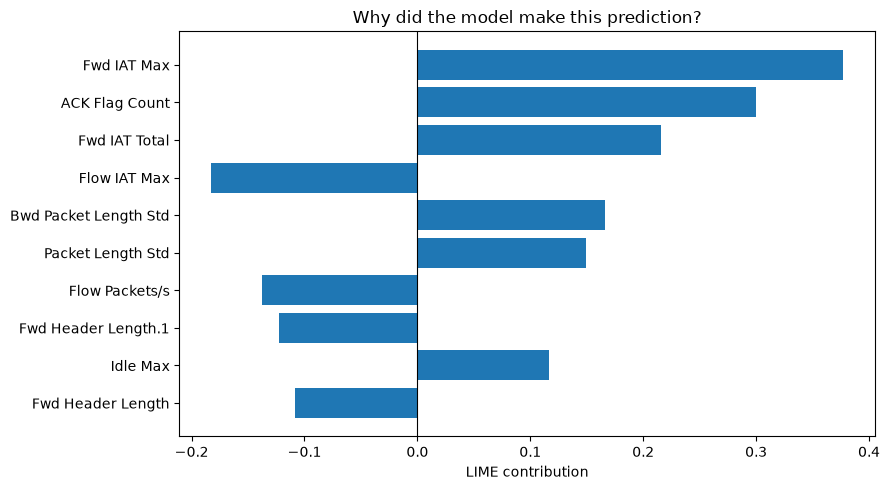

In [11]:
from xplique.attributions import Lime
import matplotlib.pyplot as plt

# نام ۷۸ ویژگی را از سربرگ CSV می‌گیریم
feature_names = [
    c.strip()
    for c in pd.read_csv(files[0], nrows=0).columns
    if c.strip() != "Label"
]

# انتخاب یک نمونه از مجموعه آزمون
sample = X_test[0:1]

score = float(model.predict(sample, verbose=0)[0, 0])
print("Attack score:", round(score, 4))
print("Prediction:", "ATTACK" if score >= 0.5 else "BENIGN")

# توضیح خروجی مدل با LIME
explainer = Lime(
    model,
    nb_samples=500,
    kernel_width=0.75 * (X_train.shape[1] ** 0.5)
)

explanation = explainer.explain(
    sample,
    targets=np.ones((1, 1), dtype=np.float32)
)

# نمایش ۱۰ ویژگی با بیشترین اثر مطلق
scores = np.asarray(explanation).reshape(-1)
top = np.argsort(np.abs(scores))[-10:]
top = top[np.argsort(np.abs(scores[top]))]

plt.figure(figsize=(9, 5))
plt.barh(
    np.array(feature_names)[top],
    scores[top]
)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("LIME contribution")
plt.title("Why did the model make this prediction?")
plt.tight_layout()
plt.show()

In [12]:
actual = int(y_test.iloc[0])
print("Actual label:", "ATTACK" if actual == 1 else "BENIGN")

Actual label: ATTACK


### LIME (Local Interpretable Model-agnostic Explanations)

LIME explains an individual prediction by approximating the behavior of a complex model with a simpler, interpretable model.

The algorithm consists of five main steps:

1. **Select an instance:** Choose a network flow whose prediction we want to explain.
2. **Generate perturbed samples:** Create variations of the selected instance by replacing some of its feature values.
3. **Obtain predictions:** Pass the perturbed samples to the trained neural network and collect their attack scores.
4. **Fit a simple model:** Train a locally weighted Ridge Regression model to approximate the neural network's behavior around the selected instance.
5. **Identify important features:** Use the coefficients of the Ridge model to identify and visualize the features that contribute most to the prediction.

The explanation is local to the selected instance and approximates the behavior of the original model rather than establishing the actual causes of an attack.

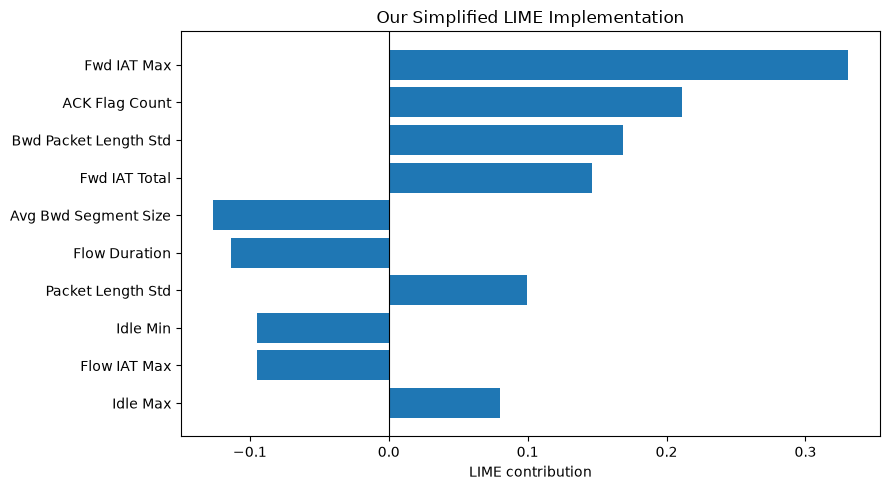

In [13]:
from sklearn.linear_model import Ridge
import numpy as np
import matplotlib.pyplot as plt

# 1. Select one test instance
sample = X_test[0:1]

# 2. Generate perturbed samples
n_samples = 500
n_features = X_train.shape[1]
rng = np.random.default_rng(42)

background = X_train[
    rng.integers(0, len(X_train), size=n_samples)
]

masks = rng.integers(
    0, 2, size=(n_samples, n_features)
).astype(np.float32)

masks[0] = 1.0

perturbed = masks * sample + (1 - masks) * background

# 3. Obtain predictions from the neural network
predictions = model.predict(
    perturbed, batch_size=128, verbose=0
).ravel()

# 4. Calculate local weights
distances = np.sqrt(np.sum((1 - masks) ** 2, axis=1))
kernel_width = 0.75 * np.sqrt(n_features)
weights = np.exp(-(distances ** 2) / (kernel_width ** 2))

# 5. Fit a weighted Ridge Regression model
lime_model = Ridge(alpha=1.0)
lime_model.fit(masks, predictions, sample_weight=weights)

# Extract feature contributions
scores = lime_model.coef_

# Display the 10 most influential features
top = np.argsort(np.abs(scores))[-10:]
top = top[np.argsort(np.abs(scores[top]))]

plt.figure(figsize=(9, 5))
plt.barh(np.array(feature_names)[top], scores[top])
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("LIME contribution")
plt.title("Our Simplified LIME Implementation")
plt.tight_layout()
plt.show()

1
